In [1]:
import struct, sys
print(struct.calcsize("P") * 8, sys.version)   # 32 means 32-bit

64 3.12.3 (v3.12.3:f6650f9ad7, Apr  9 2024, 08:18:47) [Clang 13.0.0 (clang-1300.0.29.30)]


In [1]:
# import dependencies
import sys
import json 
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import shap
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, precision_recall_curve, fbeta_score)

import warnings
warnings.filterwarnings('ignore')

In [2]:
SEED = 42
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)

In [3]:
# load data
data = pd.read_csv("data/healthcare-dataset-stroke-data.csv")
print(f"Data shape: {data.shape}")

Data shape: (5110, 12)


In [4]:
data.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [5]:
# checking columns
print(data.columns.tolist())
print(data["work_type"].value_counts(), "\n")       # spelling

['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64 



In [6]:
# feature selections
y = data["stroke"]
X = data.drop(columns=["id", "stroke"])

num_cols = ["age", "avg_glucose_level", "bmi"]
cat_cols = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
bin_cols = ["hypertension", "heart_disease"]    

In [7]:
# split stratified: 60% train, 20% validation, 20% test
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.40, stratify=y, random_state=SEED)
X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp,
                                            random_state=SEED)
for name, yy in [("train", y_tr), ("val", y_val), ("test", y_te)]:
    print(f"{name:5s} n={len(yy):5d}  stroke={yy.sum():4d} ({yy.mean():.3%})")

train n= 3066  stroke= 149 (4.860%)
val   n= 1022  stroke=  50 (4.892%)
test  n= 1022  stroke=  50 (4.892%)


## Preprocessing on TRAIN only
- median imputation (+ missing indicator) for numeric columns (bmi has NaNs)
- one-hot for categoricals, keeping 'Unknown' smoking as its own category
- no drop="first": keeps every dummy so SHAP labels stay readable

In [8]:
preprocessed = ColumnTransformer(
    [
        ("num", SimpleImputer(strategy="median", add_indicator=True), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("bin", "passthrough", bin_cols),
    ],
    verbose_feature_names_out=False,
)
preprocessed.fit(X_tr)


def transform(Xdf):
    processed_data = pd.DataFrame(preprocessed.transform(Xdf), columns=preprocessed.get_feature_names_out(), index=Xdf.index)
    return processed_data


X_tr_t, X_val_t, X_te_t = transform(X_tr), transform(X_val), transform(X_te)
print("\nTransformed features:", X_tr_t.shape[1])
print(X_tr_t.columns.tolist())
assert not X_tr_t.isna().any().any(), "NaNs remain after imputation"


Transformed features: 22
['age', 'avg_glucose_level', 'bmi', 'missingindicator_bmi', 'gender_Female', 'gender_Male', 'gender_Other', 'ever_married_No', 'ever_married_Yes', 'work_type_Govt_job', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Rural', 'Residence_type_Urban', 'smoking_status_Unknown', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes', 'hypertension', 'heart_disease']


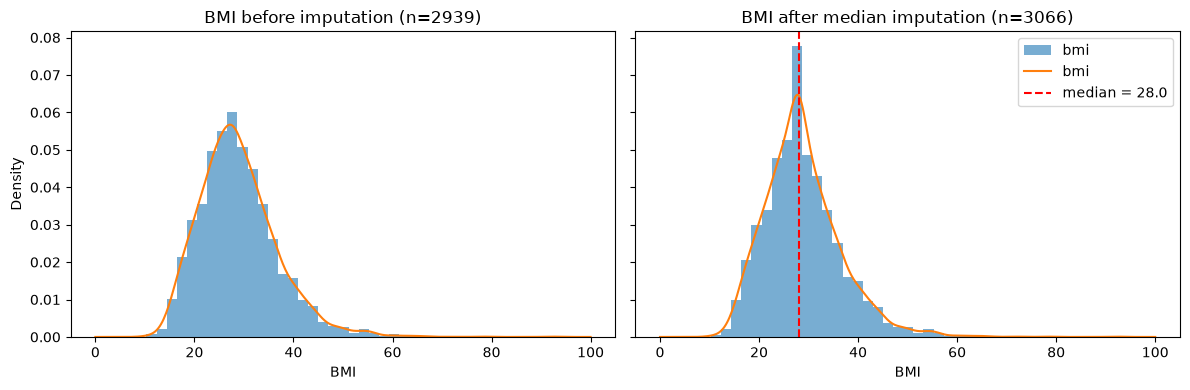

In [9]:
import numpy as np
import matplotlib.pyplot as plt

before = X_tr["bmi"].dropna()      # original values (missing rows excluded)
after = X_tr_t["bmi"]              # after median imputation
median = X_tr["bmi"].median()
grid = np.linspace(0, 100, 400)    # keeps the curve from going below 0

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)

before.plot.hist(bins=40, density=True, alpha=0.6, ax=axes[0])
before.plot.kde(ind=grid, ax=axes[0])
axes[0].set_title(f"BMI before imputation (n={len(before)})")

after.plot.hist(bins=40, density=True, alpha=0.6, ax=axes[1])
after.plot.kde(ind=grid, ax=axes[1])
axes[1].axvline(median, color="red", linestyle="--", label=f"median = {median:.1f}")
axes[1].set_title(f"BMI after median imputation (n={len(after)})")
axes[1].legend()

for ax in axes:
    ax.set_xlabel("BMI")
axes[0].set_ylabel("Density")
plt.tight_layout()
plt.show()

In [10]:
# sanity check
print(pd.crosstab(data["smoking_status"], data["work_type"]))
print(data.groupby("smoking_status")["age"].describe())
print(data.groupby("smoking_status")["stroke"].agg(["mean", "count"]))

work_type        Govt_job  Never_worked  Private  Self-employed  children
smoking_status                                                           
Unknown               122             8      640            156       618
formerly smoked       133             0      531            208        13
never smoked          282            14     1211            331        54
smokes                120             0      543            124         2
                  count       mean        std    min   25%   50%   75%   max
smoking_status                                                              
Unknown          1544.0  30.229922  25.055556   0.08   8.0  23.0  51.0  82.0
formerly smoked   885.0  54.929944  17.641723  10.00  43.0  57.0  69.0  82.0
never smoked     1892.0  46.744715  19.769584  10.00  31.0  47.0  62.0  82.0
smokes            789.0  47.096324  16.413002  10.00  33.0  47.0  59.0  82.0
                     mean  count
smoking_status                  
Unknown          0.030440   

## Training blacbox model 1: XGBoost
- Imbalance strategy: scale_pos_weight (no resampling, so no synthetic rows)

In [11]:
spw = (y_tr == 0).sum() / (y_tr == 1).sum()
model = xgb.XGBClassifier(
    n_estimators=300, max_depth=3, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=spw, eval_metric="aucpr",
    random_state=SEED, n_jobs=-1,
)
model.fit(X_tr_t, y_tr)
print("\nClasses:", model.classes_, "| scale_pos_weight:", round(spw, 2))


Classes: [0 1] | scale_pos_weight: 19.58


In [12]:
# choose decision threshold on VALIDATION data (maximise F2)
# F2 weights recall more than precision (missed strokes cost more).
p_val = model.predict_proba(X_val_t)[:, 1]
prec, rec, thr = precision_recall_curve(y_val, p_val)
f2 = (5 * prec[:-1] * rec[:-1]) / np.maximum(4 * prec[:-1] + rec[:-1], 1e-12)
threshold = float(thr[np.argmax(f2)])
print(f"Selected threshold (max F2 on validation): {threshold:.4f}")

Selected threshold (max F2 on validation): 0.2485


In [13]:
# evaluate ONCE on the untouched test set
p_te = model.predict_proba(X_te_t)[:, 1]
y_hat = (p_te >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_te, y_hat).ravel()
metrics = {
    "threshold": threshold,
    "accuracy": accuracy_score(y_te, y_hat),
    "balanced_accuracy": balanced_accuracy_score(y_te, y_hat),
    "precision_stroke": precision_score(y_te, y_hat, zero_division=0),
    "recall_stroke": recall_score(y_te, y_hat),
    "f1_stroke": f1_score(y_te, y_hat),
    "f2_stroke": fbeta_score(y_te, y_hat, beta=2),
    "roc_auc": roc_auc_score(y_te, p_te),
    "average_precision": average_precision_score(y_te, p_te),
    "prevalence_test": float(y_te.mean()),
    "support_positive": int(y_te.sum()),
    "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
}
print("\nTEST METRICS")
for k, v in metrics.items():
    print(f"  {k:20s} {v:.4f}" if isinstance(v, float) else f"  {k:20s} {v}")
(OUT / "task2_metrics.json").write_text(json.dumps(metrics, indent=2))


TEST METRICS
  threshold            0.2485
  accuracy             0.6957
  balanced_accuracy    0.7452
  precision_stroke     0.1173
  recall_stroke        0.8000
  f1_stroke            0.2046
  f2_stroke            0.3697
  roc_auc              0.8207
  average_precision    0.2605
  prevalence_test      0.0489
  support_positive     50
  TN                   671
  FP                   301
  FN                   10
  TP                   40


447

## SHAP explainer + verification
- TreeExplainer on XGBoost explains the raw margin (LOG-ODDS) of class 1.
- Background: default tree-path-dependent (no background needed). 
- For interventional SHAP, pass data=shap.sample(X_tr_t, 100, random_state=SEED) and feature_perturbation="interventional".

In [14]:
explainer = shap.TreeExplainer(model)
sv = explainer(X_te_t)                      # Explanation: .values .base_values .data
print("\nSHAP values shape:", sv.values.shape, "(rows, features)")
assert sv.values.shape == X_te_t.shape
assert list(sv.feature_names) == list(X_te_t.columns), "feature order mismatch"

recon = sv.base_values + sv.values.sum(axis=1)                 # log-odds
margin = model.predict(X_te_t, output_margin=True)              # model's log-odds
resid = np.abs(recon - margin)
print(f"Base value (log-odds): {float(np.mean(sv.base_values)):.4f} "
      f"= probability {1/(1+np.exp(-float(np.mean(sv.base_values)))):.4f}")
print(f"Max |reconstruction - model margin|: {resid.max():.2e}  (tolerance 1e-4)")
assert resid.max() < 1e-4, "SHAP additivity check failed"
# Probability check (apply sigmoid to the LOG-ODDS sum, never add to a probability)
p_recon = 1 / (1 + np.exp(-recon))
print(f"Max |sigmoid(recon) - predict_proba|: {np.abs(p_recon - p_te).max():.2e}")

np.save(OUT / "shap_values_test.npy", sv.values)
X_te_t.to_csv(OUT / "X_test_transformed.csv")


SHAP values shape: (1022, 22) (rows, features)
Base value (log-odds): 0.4276 = probability 0.6053
Max |reconstruction - model margin|: 6.20e-06  (tolerance 1e-4)
Max |sigmoid(recon) - predict_proba|: 3.87e-07


## Task 3
- highest-scoring true positive in the test set. 
- Fall back to the highest-scoring case if there is none.

In [13]:
# local explanation for ONE held-out case
pos = np.where((y_te.values == 1) & (y_hat == 1))[0]
if len(pos):
    i = int(pos[np.argmax(p_te[pos])])
    case_type = "True positive"
else:
    i = int(np.argmax(p_te))
    case_type = "Highest-scoring case (no true positive)"
row_id = X_te_t.index[i]                                   # original row index
base = float(sv.base_values[i])
out_logit = float(sv.base_values[i] + sv.values[i].sum())

print(f"\nTask 3 case: test position {i}, original row {row_id}, {case_type}")
print(f"  actual={int(y_te.iloc[i])}, predicted={int(y_hat[i])}, threshold={threshold:.4f}")
print(f"  probability={p_te[i]:.4f}, log-odds output={out_logit:.4f}, base value={base:.4f}")

# Static force plot (for the Word report)
shap.force_plot(base, sv.values[i], X_te_t.iloc[i].round(2),
                matplotlib=True, show=False, figsize=(20, 3.5), text_rotation=20)
plt.savefig(OUT / "task3_force_plot.png", dpi=200, bbox_inches="tight")
plt.close()

# Interactive HTML (optional extra)
shap.save_html(str(OUT / "task3_force_plot.html"),
               shap.force_plot(base, sv.values[i], X_te_t.iloc[i]))

# Contribution table: top 3 by |SHAP|, plus the rest combined
contrib = pd.DataFrame({
    "feature": X_te_t.columns,
    "patient_value": X_te_t.iloc[i].values,
    "shap_logodds": sv.values[i],
})
contrib["direction"] = np.where(contrib["shap_logodds"] > 0, "Increases", "Decreases")
contrib = contrib.reindex(contrib["shap_logodds"].abs().sort_values(ascending=False).index)
top3, rest = contrib.head(3), contrib.iloc[3:]
table = pd.concat([top3, pd.DataFrame([{
    "feature": "Remaining features combined", "patient_value": np.nan,
    "shap_logodds": rest["shap_logodds"].sum(),
    "direction": "Increases" if rest["shap_logodds"].sum() > 0 else "Decreases",
}])], ignore_index=True)
print("\nTask 3 contribution table (log-odds scale):")
print(table.round(4).to_string(index=False))
table.to_csv(OUT / "task3_contributions.csv", index=False)
print("\nAll positive-direction features:", contrib[contrib.shap_logodds > 0].head(3)["feature"].tolist())
print("All negative-direction features:", contrib[contrib.shap_logodds < 0].head(3)["feature"].tolist())


Task 3 case: test position 34, original row 61, True positive
  actual=1, predicted=1, threshold=0.2485
  probability=0.9624, log-odds output=3.2416, base value=0.4276

Task 3 contribution table (log-odds scale):
                    feature  patient_value  shap_logodds direction
                        age           80.0        2.3368 Increases
               hypertension            1.0        0.4636 Increases
          avg_glucose_level           74.9        0.2376 Increases
Remaining features combined            NaN       -0.2241 Decreases

All positive-direction features: ['age', 'hypertension', 'avg_glucose_level']
All negative-direction features: ['bmi', 'smoking_status_never smoked', 'missingindicator_bmi']


In [15]:
# held-out case, save to json
pos = np.where((y_te.values == 1) & (y_hat == 1))[0]
if len(pos):
    i = int(pos[np.argmax(p_te[pos])])
    case_type = "True positive"
else:
    i = int(np.argmax(p_te))
    case_type = "Highest-scoring case (no true positive)"
row_id = X_te_t.index[i]                                   # original row index
base = float(sv.base_values[i])
out_logit = float(sv.base_values[i] + sv.values[i].sum())

print(f"\nTask 3 case: test position {i}, original row {row_id}, {case_type}")
print(f"  actual={int(y_te.iloc[i])}, predicted={int(y_hat[i])}, threshold={threshold:.4f}")
print(f"  probability={p_te[i]:.4f}, log-odds output={out_logit:.4f}, base value={base:.4f}")

# Save everything Section 4.1 of the report asks for
actual, pred = int(y_te.iloc[i]), int(y_hat[i])
case_label = {(1, 1): "True positive", (0, 1): "False positive",
              (0, 0): "True negative", (1, 0): "False negative"}[(actual, pred)]
case_summary = {
    "anonymous_row_reference": f"test-set row index {row_id}",
    "selection_rule": "highest-scoring true positive in the test set",
    "actual_class": actual, "predicted_class": pred, "case_type": case_label,
    "threshold": threshold, "model_probability_score": float(p_te[i]),
    "explained_output": "log-odds (raw margin) of stroke = 1",
    "output_value_logodds": out_logit, "base_value_logodds": base,
}
(OUT / "task3_case_summary.json").write_text(json.dumps(case_summary, indent=2))

# Static force plot (for the Word report)
shap.force_plot(base, sv.values[i], X_te_t.iloc[i].round(2),
                matplotlib=True, show=False, figsize=(20, 3.5), text_rotation=20)
plt.savefig(OUT / "task3_force_plot.png", dpi=200, bbox_inches="tight")
plt.close()

# Interactive HTML (optional extra)
shap.save_html(str(OUT / "task3_force_plot.html"),
               shap.force_plot(base, sv.values[i], X_te_t.iloc[i]))

# Contribution table: top 3 by |SHAP|, plus the rest combined
contrib = pd.DataFrame({
    "feature": X_te_t.columns,
    "patient_value": X_te_t.iloc[i].values,
    "shap_logodds": sv.values[i],
})
contrib["direction"] = np.where(contrib["shap_logodds"] > 0, "Increases", "Decreases")
contrib = contrib.reindex(contrib["shap_logodds"].abs().sort_values(ascending=False).index)
top3, rest = contrib.head(3), contrib.iloc[3:]
table = pd.concat([top3, pd.DataFrame([{
    "feature": "Remaining features combined", "patient_value": np.nan,
    "shap_logodds": rest["shap_logodds"].sum(),
    "direction": "Increases" if rest["shap_logodds"].sum() > 0 else "Decreases",
}])], ignore_index=True)
print("\nTask 3 contribution table (log-odds scale):")
print(table.round(4).to_string(index=False))
table.to_csv(OUT / "task3_contributions.csv", index=False)
print("\nAll positive-direction features:", contrib[contrib.shap_logodds > 0].head(3)["feature"].tolist())
print("All negative-direction features:", contrib[contrib.shap_logodds < 0].head(3)["feature"].tolist())



Task 3 case: test position 34, original row 61, True positive
  actual=1, predicted=1, threshold=0.2485
  probability=0.9624, log-odds output=3.2416, base value=0.4276

Task 3 contribution table (log-odds scale):
                    feature  patient_value  shap_logodds direction
                        age           80.0        2.3368 Increases
               hypertension            1.0        0.4636 Increases
          avg_glucose_level           74.9        0.2376 Increases
Remaining features combined            NaN       -0.2241 Decreases

All positive-direction features: ['age', 'hypertension', 'avg_glucose_level']
All negative-direction features: ['bmi', 'smoking_status_never smoked', 'missingindicator_bmi']


In [16]:
# GLOBAL EXPLANATION (XGBoost, log-odds scale, full held-out test set)
print("\n" + "=" * 78 + "\nTASK 4: GLOBAL SUMMARY PLOT\n" + "=" * 78)

# 4.1 Beeswarm summary plot (required) -- features ranked by mean |SHAP|
shap.summary_plot(sv.values, X_te_t, max_display=15, show=False)
plt.xlabel("SHAP value (impact on log-odds of stroke = 1)")
plt.savefig(OUT / "task4_summary_beeswarm.png", dpi=200, bbox_inches="tight")
plt.close()

# 4.2 Mean |SHAP| bar chart (supplementary)
shap.summary_plot(sv.values, X_te_t, plot_type="bar", max_display=15, show=False)
plt.xlabel("Mean |SHAP value| (log-odds)")
plt.savefig(OUT / "task4_mean_abs_bar.png", dpi=200, bbox_inches="tight")
plt.close()

# 4.3 Importance table for the report (encoded columns)
mean_abs = pd.Series(np.abs(sv.values).mean(axis=0), index=X_te_t.columns).sort_values(ascending=False)


def describe_pattern(feature):
    """Direction of the relationship between feature value and its SHAP value."""
    j = X_te_t.columns.get_loc(feature)
    x, s = X_te_t[feature].values, sv.values[:, j]
    if np.std(x) == 0 or np.std(s) == 0:
        return "constant / no variation"
    r = np.corrcoef(x, s)[0, 1]
    if r > 0.3:
        return f"higher values -> higher output (r={r:.2f})"
    if r < -0.3:
        return f"higher values -> lower output (r={r:.2f})"
    return f"mixed / non-monotonic (r={r:.2f})"


imp_table = pd.DataFrame({
    "rank": np.arange(1, len(mean_abs) + 1),
    "feature": mean_abs.index,
    "mean_abs_shap": mean_abs.values,
    "observed_pattern": [describe_pattern(f) for f in mean_abs.index],
})
imp_table.to_csv(OUT / "task4_importance_table.csv", index=False)
print("Held-out explanation sample:", len(X_te_t), "cases,", int(y_te.sum()), "positive")
print(imp_table.head(10).round(4).to_string(index=False))

# 4.4 Grouped importance: sum the SIGNED SHAP values of one-hot columns per case
#     FIRST, then take the mean absolute value (the template's aggregation rule).
groups = {c: [col for col in X_te_t.columns if col.startswith(c + "_")] for c in cat_cols}
grouped_cols = {col for cols in groups.values() for col in cols}


def grouped_importance(values, columns):
    sv_df = pd.DataFrame(values, columns=columns)
    out = {g: sv_df[cols].sum(axis=1).abs().mean() for g, cols in groups.items()}
    out.update({c: sv_df[c].abs().mean() for c in columns if c not in grouped_cols})
    return pd.Series(out).sort_values(ascending=False)


grouped = grouped_importance(sv.values, X_te_t.columns)
grouped.to_csv(OUT / "task4_grouped_importance.csv", header=["mean_abs_shap"])
ax = grouped.head(12).iloc[::-1].plot.barh(figsize=(7, 5), edgecolor="black")
ax.set_xlabel("Mean |grouped SHAP value| (log-odds)")
ax.set_title("Grouped global importance (one-hot columns summed per case)")
plt.tight_layout()
plt.savefig(OUT / "task4_grouped_bar.png", dpi=200, bbox_inches="tight")
plt.close()
print("\nGrouped importance (top 8):\n", grouped.head(8).round(4).to_string())

# 4.5 Link the Task 3 case to the global pattern
rank_of = {f: r + 1 for r, f in enumerate(mean_abs.index)}
link_rows = []
for f in contrib.head(5)["feature"]:
    j = X_te_t.columns.get_loc(f)
    s_case = float(sv.values[i, j])
    pct = float((np.abs(sv.values[:, j]) < abs(s_case)).mean() * 100)
    link_rows.append({"feature": f, "global_rank": rank_of[f], "case_value": X_te_t.iloc[i][f],
                      "case_shap": s_case, "case_direction": "up" if s_case > 0 else "down",
                      "global_pattern": describe_pattern(f),
                      "case_|shap|_percentile": round(pct, 1)})
link = pd.DataFrame(link_rows)
link.to_csv(OUT / "task4_case_vs_global.csv", index=False)
print("\nTask 3 case vs global pattern:\n", link.round(3).to_string(index=False))


TASK 4: GLOBAL SUMMARY PLOT
Held-out explanation sample: 1022 cases, 50 positive
 rank                     feature  mean_abs_shap                        observed_pattern
    1                         age         3.0377 higher values -> higher output (r=0.93)
    2                         bmi         0.8176 higher values -> higher output (r=0.39)
    3           avg_glucose_level         0.4652          mixed / non-monotonic (r=0.25)
    4                hypertension         0.1367 higher values -> higher output (r=0.91)
    5      smoking_status_Unknown         0.0924 higher values -> lower output (r=-0.93)
    6     work_type_Self-employed         0.0899 higher values -> lower output (r=-0.94)
    7 smoking_status_never smoked         0.0871 higher values -> lower output (r=-0.93)
    8       smoking_status_smokes         0.0854 higher values -> higher output (r=0.93)
    9        Residence_type_Rural         0.0803 higher values -> higher output (r=0.46)
   10        missingindicato

## Second black-box: RBF-SVM Kernel SHAP

In [17]:
import time
from scipy.stats import spearmanr
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

In [18]:
# Kernel SHAP settings
N_EXPLAIN = 200        # held-out cases to explain (includes the Task 3 case)
N_BG = 50              # background: random real training rows
NSAMPLES = 500         # coalition samples per explained case
RUN_STABILITY = True   # repeat with a different background sample
N_STAB = 60            # cases used in the stability check

In [19]:
# SVM needs scaled inputs. Scale numeric columns only, fitted on TRAIN only.
scaler = StandardScaler().fit(X_tr_t[num_cols])

def scale(Xdf):
    Z = Xdf.copy()
    Z[num_cols] = scaler.transform(Xdf[num_cols])
    return Z


X_tr_s, X_val_s, X_te_s = scale(X_tr_t), scale(X_val_t), scale(X_te_t)

In [20]:
# Train. class_weight="balanced" = same imbalance idea as scale_pos_weight.
svm = SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced",
          probability=True, random_state=SEED)
svm.fit(X_tr_s, y_tr)
print("SVM classes:", svm.classes_)

SVM classes: [0 1]


In [21]:
# Same threshold rule (max F2 on validation) and same test evaluation
p_val2 = svm.predict_proba(X_val_s)[:, 1]
prec2, rec2, thr2 = precision_recall_curve(y_val, p_val2)
f2_2 = (5 * prec2[:-1] * rec2[:-1]) / np.maximum(4 * prec2[:-1] + rec2[:-1], 1e-12)
threshold2 = float(thr2[np.argmax(f2_2)])

p_te2 = svm.predict_proba(X_te_s)[:, 1]
y_hat2 = (p_te2 >= threshold2).astype(int)
tn2, fp2, fn2, tp2 = confusion_matrix(y_te, y_hat2).ravel()
metrics2 = {
    "threshold": threshold2,
    "accuracy": accuracy_score(y_te, y_hat2),
    "balanced_accuracy": balanced_accuracy_score(y_te, y_hat2),
    "precision_stroke": precision_score(y_te, y_hat2, zero_division=0),
    "recall_stroke": recall_score(y_te, y_hat2),
    "f1_stroke": f1_score(y_te, y_hat2),
    "f2_stroke": fbeta_score(y_te, y_hat2, beta=2),
    "roc_auc": roc_auc_score(y_te, p_te2),
    "average_precision": average_precision_score(y_te, p_te2),
    "prevalence_test": float(y_te.mean()),
    "support_positive": int(y_te.sum()),
    "TN": int(tn2), "FP": int(fp2), "FN": int(fn2), "TP": int(tp2),
}
(OUT / "task6_metrics.json").write_text(json.dumps(metrics2, indent=2))
print("\nSVM TEST METRICS")
for k, v in metrics2.items():
    print(f"  {k:20s} {v:.4f}" if isinstance(v, float) else f"  {k:20s} {v}")


SVM TEST METRICS
  threshold            0.0523
  accuracy             0.7045
  balanced_accuracy    0.7213
  precision_stroke     0.1135
  recall_stroke        0.7400
  f1_stroke            0.1968
  f2_stroke            0.3517
  roc_auc              0.7816
  average_precision    0.1626
  prevalence_test      0.0489
  support_positive     50
  TN                   683
  FP                   289
  FN                   13
  TP                   37


## Kernel SHAP

In [22]:
f = lambda d: svm.predict_proba(pd.DataFrame(d, columns=X_tr_s.columns))[:, 1]

rng = np.random.default_rng(SEED)
others = np.setdiff1d(np.arange(len(X_te_s)), [i])
idx_explain = np.sort(np.r_[i, rng.choice(others, size=min(N_EXPLAIN - 1, len(others)),
                                         replace=False)])
k_case = int(np.where(idx_explain == i)[0][0])          # Task 3 case inside the sample
X_ex_s, X_ex_raw = X_te_s.iloc[idx_explain], X_te_t.iloc[idx_explain]
y_ex = y_te.iloc[idx_explain]
print(f"\nExplaining {len(idx_explain)} held-out cases ({int(y_ex.sum())} positive); "
      f"background={N_BG}, nsamples={NSAMPLES}")

bg = shap.sample(X_tr_s, N_BG, random_state=SEED)
kex = shap.KernelExplainer(f, bg)
t0 = time.perf_counter()
sv2 = np.asarray(kex.shap_values(X_ex_s, nsamples=NSAMPLES, l1_reg=0))
runtime = time.perf_counter() - t0
if sv2.ndim == 3:                                        # some versions add an output axis
    sv2 = sv2[..., 0]
base2 = float(np.ravel(kex.expected_value)[0])
print(f"Kernel SHAP runtime: {runtime:.1f}s | SHAP shape: {sv2.shape} | base value: {base2:.4f}")


Explaining 200 held-out cases (10 positive); background=50, nsamples=500


  0%|          | 0/200 [00:00<?, ?it/s]

Kernel SHAP runtime: 409.1s | SHAP shape: (200, 22) | base value: 0.0566


In [23]:
# Verification: base + sum(SHAP) should equal the SVM probability
fx = f(X_ex_s)
resid2 = np.abs(base2 + sv2.sum(axis=1) - fx)
print(f"Max |base + sum(SHAP) - SVM probability|: {resid2.max():.2e} "
      f"(mean {resid2.mean():.2e})")
np.save(OUT / "task6_shap_values.npy", sv2)

Max |base + sum(SHAP) - SVM probability|: 8.33e-17 (mean 6.60e-18)


In [30]:
# Local explanation
shap.force_plot(base2, sv2[k_case], X_te_t.iloc[i].round(2),
                matplotlib=True, show=False, figsize=(24, 4), text_rotation=20, contribution_threshold=0.08)
plt.savefig(OUT / "task6_force_plot.png", dpi=200, bbox_inches="tight")
plt.close()
print(f"\nTask 6 local case (row {row_id}): SVM probability={p_te2[i]:.4f}, "
      f"predicted={int(y_hat2[i])}, threshold={threshold2:.4f}, base={base2:.4f}")


Task 6 local case (row 61): SVM probability=0.1502, predicted=1, threshold=0.0523, base=0.0566


In [25]:
# Global explanation 
shap.summary_plot(sv2, X_ex_raw, max_display=15, show=False)
plt.xlabel("SHAP value (impact on SVM probability of stroke = 1)")
plt.savefig(OUT / "task6_summary_beeswarm.png", dpi=200, bbox_inches="tight")
plt.close()

mean_abs2 = pd.Series(np.abs(sv2).mean(axis=0), index=X_te_t.columns).sort_values(ascending=False)
imp2 = pd.DataFrame({"rank": np.arange(1, len(mean_abs2) + 1), "feature": mean_abs2.index,
                     "mean_abs_shap_probability": mean_abs2.values})
imp2.to_csv(OUT / "task6_importance_table.csv", index=False)
grouped2 = grouped_importance(sv2, X_te_t.columns)
grouped2.to_csv(OUT / "task6_grouped_importance.csv", header=["mean_abs_shap"])
print("\nSVM global importance (top 8, probability scale):\n",
      imp2.head(8).round(4).to_string(index=False))


SVM global importance (top 8, probability scale):
  rank                     feature  mean_abs_shap_probability
    1                         age                     0.0360
    2                         bmi                     0.0070
    3           avg_glucose_level                     0.0046
    4     work_type_Self-employed                     0.0044
    5 smoking_status_never smoked                     0.0042
    6      smoking_status_Unknown                     0.0041
    7        missingindicator_bmi                     0.0041
    8           work_type_Private                     0.0032


## Comparison 
- same sample, rankings and signs only
- log-odds vs probability magnitudes are NOT comparable

In [26]:
print("\n" + "=" * 78 + "\nCOMPARISON: XGBoost (Task 2) vs SVM (Task 6)\n" + "=" * 78)
sv_xgb_ex = sv.values[idx_explain]
mean_abs_x = pd.Series(np.abs(sv_xgb_ex).mean(axis=0), index=X_te_t.columns)
rho, _ = spearmanr(mean_abs_x.values, mean_abs2.reindex(X_te_t.columns).values)
top3_x, top3_s = list(mean_abs_x.sort_values(ascending=False).index[:3]), list(mean_abs2.index[:3])
print(f"Spearman rank correlation of mean|SHAP| (same {len(idx_explain)} cases): {rho:.3f}")
print("Top 3 XGBoost:", top3_x, "| Top 3 SVM:", top3_s)

case_cmp = pd.DataFrame({
    "feature": X_te_t.columns,
    "patient_value": X_te_t.iloc[i].values,
    "xgb_shap_logodds": sv.values[i],
    "svm_shap_probability": sv2[k_case],
})
case_cmp["same_sign"] = np.sign(case_cmp.xgb_shap_logodds) == np.sign(case_cmp.svm_shap_probability)
case_cmp = case_cmp.reindex(case_cmp.xgb_shap_logodds.abs().sort_values(ascending=False).index)
case_cmp.to_csv(OUT / "task6_case_comparison.csv", index=False)
print("\nSame case, both models (top 8 by XGBoost |SHAP|):\n", case_cmp.head(8).round(4).to_string(index=False))

cmp_tbl = pd.DataFrame({"XGBoost (Task 2)": metrics, "SVM (Task 6)": metrics2})
cmp_tbl.loc["case_score_probability"] = [float(p_te[i]), float(p_te2[i])]
cmp_tbl.loc["explained_scale"] = ["log-odds", "probability"]
cmp_tbl.loc["spearman_importance_rank"] = [rho, rho]
cmp_tbl.loc["shap_runtime_s"] = ["seconds (TreeExplainer)", round(runtime, 1)]
cmp_tbl.to_csv(OUT / "comparison_table.csv")


COMPARISON: XGBoost (Task 2) vs SVM (Task 6)
Spearman rank correlation of mean|SHAP| (same 200 cases): 0.784
Top 3 XGBoost: ['age', 'bmi', 'avg_glucose_level'] | Top 3 SVM: ['age', 'bmi', 'avg_glucose_level']

Same case, both models (top 8 by XGBoost |SHAP|):
                        feature  patient_value  xgb_shap_logodds  svm_shap_probability  same_sign
                           age           80.0            2.3368                0.0912       True
                  hypertension            1.0            0.4636               -0.0151      False
             avg_glucose_level           74.9            0.2376                0.0092       True
                           bmi           22.2           -0.1619               -0.0079       True
   smoking_status_never smoked            1.0           -0.1580               -0.0127       True
          Residence_type_Rural            1.0            0.1201                0.0069       True
          missingindicator_bmi            0.0           -0.

## Stability 
- repeat Kernel SHAP with a different background sample

In [27]:
if RUN_STABILITY:
    print("\n" + "=" * 78 + "\nSTABILITY: different background sample\n" + "=" * 78)
    pos_stab = np.unique(np.r_[k_case, np.arange(min(N_STAB, len(idx_explain)))])
    bg_b = shap.sample(X_tr_s, N_BG, random_state=SEED + 1)
    kex_b = shap.KernelExplainer(f, bg_b)
    sv2b = np.asarray(kex_b.shap_values(X_ex_s.iloc[pos_stab], nsamples=NSAMPLES, l1_reg=0))
    if sv2b.ndim == 3:
        sv2b = sv2b[..., 0]
    ma_a = pd.Series(np.abs(sv2[pos_stab]).mean(axis=0), index=X_te_t.columns)
    ma_b = pd.Series(np.abs(sv2b).mean(axis=0), index=X_te_t.columns)
    rho_b, _ = spearmanr(ma_a.values, ma_b.values)
    top5_a = list(ma_a.sort_values(ascending=False).index[:5])
    top5_b = list(ma_b.sort_values(ascending=False).index[:5])
    kc = int(np.where(pos_stab == k_case)[0][0])
    sign_changes = [feat for feat in X_te_t.columns
                    if abs(sv2[k_case, X_te_t.columns.get_loc(feat)]) > 0.01
                    and np.sign(sv2[k_case, X_te_t.columns.get_loc(feat)])
                    != np.sign(sv2b[kc, X_te_t.columns.get_loc(feat)])]
    print(f"Spearman (original vs new background, {len(pos_stab)} cases): {rho_b:.3f}")
    print("Top 5 (seed A):", top5_a, "\nTop 5 (seed B):", top5_b)
    print("Top-5 overlap:", len(set(top5_a) & set(top5_b)), "/ 5")
    print("Task 3 case features (|SHAP|>0.01) whose sign changed:", sign_changes or "none")
    json.dump({"spearman": rho_b, "top5_a": top5_a, "top5_b": top5_b,
               "case_sign_changes": sign_changes, "n_cases": int(len(pos_stab))},
              open(OUT / "task6_stability.json", "w"), indent=2)


STABILITY: different background sample


  0%|          | 0/60 [00:00<?, ?it/s]

Spearman (original vs new background, 60 cases): 0.815
Top 5 (seed A): ['age', 'bmi', 'avg_glucose_level', 'work_type_Self-employed', 'smoking_status_Unknown'] 
Top 5 (seed B): ['age', 'bmi', 'avg_glucose_level', 'smoking_status_never smoked', 'smoking_status_smokes']
Top-5 overlap: 3 / 5
Task 3 case features (|SHAP|>0.01) whose sign changed: none


## Reproducibility report

In [28]:
env = {
    "python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__,
    "scikit-learn": sklearn.__version__, "xgboost": xgb.__version__, "shap": shap.__version__,
    "seed": SEED, "split": "60/20/20 stratified",
    "train_idx_first5": X_tr.index[:5].tolist(),
}
(OUT / "environment.json").write_text(json.dumps(env, indent=2))
print("\nSaved outputs to", OUT.resolve())



Saved outputs to /Users/alyani/Desktop/grad school/xai-series-master/outputs


In [29]:
# Extra settings for the reproducibility appendix
json.dump({"svm": svm.get_params(), "kernel_shap": {"n_explain": N_EXPLAIN, "n_background": N_BG,
          "nsamples": NSAMPLES, "l1_reg": 0, "seed": SEED, "runtime_s": runtime,
          "max_additivity_residual": float(resid2.max())}},
          open(OUT / "task6_settings.json", "w"), indent=2, default=str)
print("\nAll Task 4 and Task 6 outputs saved to", OUT.resolve())


All Task 4 and Task 6 outputs saved to /Users/alyani/Desktop/grad school/xai-series-master/outputs
